# When do code switches happen, and how long do they last?

Exploratory analysis of the **per-token switch and duration labels** for SwitchLingua (234,172 conversations, 15 language pairs). Everything is broken down by language pair.

1. **Overview:** how much switching each pair has, in each direction.
2. **When switches happen:** after how long in a language, where in the conversation, and what comes just before.
3. **How long switches last:** run lengths and the Small / Medium / Large classes, in words and in XLM-R pieces.
4. **Speaker and conversation attributes:** age, gender, education, topic, and the requested switching style.
5. **Takeaways for the model.**

Terms used throughout:
- **L1 / L2.** L1 is the pair's first language; L2 is its second, English for every pair except German→French.
- **A switch** is a token whose *next* token is in the other language (`y_sw = 1`).
- **Its duration (`y_len`)** is how many tokens the new language then lasts.
- **Classes:** Small 1–2, Medium 3–6, Large 7+.
- **Tokens are words,** except Chinese, Japanese, Korean and Cantonese, which are counted per character.

> **SwitchLingua is generated by a language model.** Each conversation was written by a model prompted with a speaker persona (age, gender, education) and a switching style (ratio, type, function). Section 4 therefore measures **how the generator responds to those prompts**, not how real people of that age or background switch.

## Setup

In [1]:
import glob, os, subprocess, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                                   # run from the repo root
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

WORD = "data/final/token_labels_word.parquet"
PIECE = "data/final/token_labels_subword.parquet"
if not (os.path.exists(WORD) and os.path.exists(PIECE)):
    subprocess.run([sys.executable, "scripts/download_labels.py"], check=True)

PAIR_ORDER = None   # filled after loading: pairs sorted by switch rate
def pair_name(l1, l2):
    return l1 if l2 == "English" else f"{l1}→{l2}"

In [2]:
# Word-level labels: one row per conversation, lists aligned to its tokens.
w = pd.read_parquet(WORD, columns=["row_id", "first_language", "second_language", "split",
                                   "tokens", "lang", "y_sw", "y_len", "y_dur", "censored", "dur_known"])
w["pair"] = [pair_name(a, b) for a, b in zip(w.first_language, w.second_language)]
print(f"{len(w):,} conversations")

# Flatten to one entry per token (numpy arrays, aligned).
n_tok = w.tokens.map(len).to_numpy()
row = np.repeat(np.arange(len(w)), n_tok)
T = dict(
    row=row,
    pair=np.repeat(w.pair.to_numpy(), n_tok),
    tok=np.concatenate([np.asarray(x, dtype=object) for x in w.tokens]),
    lang=np.concatenate([np.asarray(x, dtype=object) for x in w.lang]),
    y_sw=np.concatenate([np.asarray(x) for x in w.y_sw]).astype(np.int8),
    y_len=np.concatenate([np.asarray(x) for x in w.y_len]).astype(np.int32),
    y_dur=np.concatenate([np.asarray(x, dtype=object) for x in w.y_dur]),
    censored=np.concatenate([np.asarray(x) for x in w.censored]).astype(bool),
    dur_known=np.concatenate([np.asarray(x) for x in w.dur_known]).astype(bool),
)
T["pos"] = np.concatenate([np.arange(n) for n in n_tok])          # index within the row
T["rel"] = T["pos"] / np.repeat(np.maximum(n_tok - 1, 1), n_tok)  # 0 = start, 1 = end
scored = T["y_sw"] >= 0
sw = T["y_sw"] == 1
print(f"{len(T['tok']):,} tokens | {scored.sum():,} scored | {sw.sum():,} switches ({sw.sum()/scored.sum():.2%})")

234,172 conversations


22,349,157 tokens | 19,365,955 scored | 1,896,078 switches (9.79%)


## 1. Overview: how much switching, by pair and direction

In [3]:
# Direction of a switch: from the current token's language into the other.
into_l2 = sw & (T["lang"] == "L1")
into_l1 = sw & (T["lang"] == "L2")
g = pd.DataFrame({"pair": T["pair"], "scored": scored, "sw": sw, "into_l2": into_l2, "into_l1": into_l1,
                  "in_l1": scored & (T["lang"] == "L1"), "in_l2": scored & (T["lang"] == "L2")})
ov = g.groupby("pair").sum()
ov["switch rate"] = ov.sw / ov.scored
ov["P(→L2 | in L1)"] = ov.into_l2 / ov.in_l1
ov["P(→L1 | in L2)"] = ov.into_l1 / ov.in_l2
ov["L2 share"] = ov.in_l2 / (ov.in_l1 + ov.in_l2)
ov = ov.sort_values("switch rate")
PAIR_ORDER = list(ov.index)
conv = w.groupby("pair").size().rename("conversations")
show = ov.join(conv)[["conversations", "scored", "sw", "switch rate", "P(→L2 | in L1)", "P(→L1 | in L2)", "L2 share"]]
show.style.format({"conversations": "{:,}", "scored": "{:,}", "sw": "{:,}", "switch rate": "{:.1%}",
                   "P(→L2 | in L1)": "{:.1%}", "P(→L1 | in L2)": "{:.1%}", "L2 share": "{:.1%}"})

,conversations,scored,sw,switch rate,P(→L2 | in L1),P(→L1 | in L2),L2 share
pair,,,,,,,
Japanese,"8,385","947,612","55,896",5.9%,4.2%,11.8%,22.0%
Korean,"8,266","723,937","52,236",7.2%,5.3%,13.6%,22.9%
Chinese,"8,458","811,428","58,833",7.3%,5.5%,12.2%,26.1%
Cantonese,"119,248","12,198,723","1,050,873",8.6%,5.6%,22.5%,17.9%
Spanish,"8,110","437,351","46,921",10.7%,9.2%,13.9%,33.2%
Vietnamese,"8,457","566,038","61,001",10.8%,8.5%,16.3%,29.3%
Italian,"7,979","420,929","45,454",10.8%,9.7%,12.7%,36.1%
French,"8,070","415,522","45,494",10.9%,9.6%,13.5%,34.5%
German,"6,819","326,296","38,936",11.9%,10.6%,14.4%,35.3%


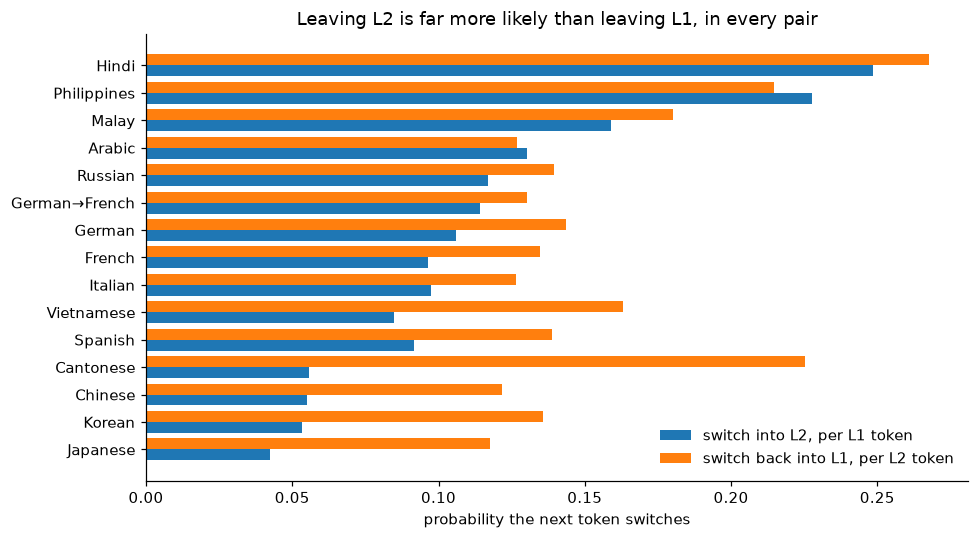

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(ov))
ax.barh(y - 0.2, ov["P(→L2 | in L1)"], 0.4, label="switch into L2, per L1 token")
ax.barh(y + 0.2, ov["P(→L1 | in L2)"], 0.4, label="switch back into L1, per L2 token")
ax.set_yticks(y, ov.index); ax.set_xlabel("probability the next token switches")
ax.set_title("Leaving L2 is far more likely than leaving L1, in every pair")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

**Reading it.** In every pair, a token in the second language is several times more likely to be followed by a switch than a token in the first language. Second-language stretches are short excursions, and the first language is the base the speaker returns to. Hindi and Tagalog switch the most, Japanese and Chinese the least (in characters).

## 2. When do switches happen?

### 2a. After how long in the current language? (the hazard)

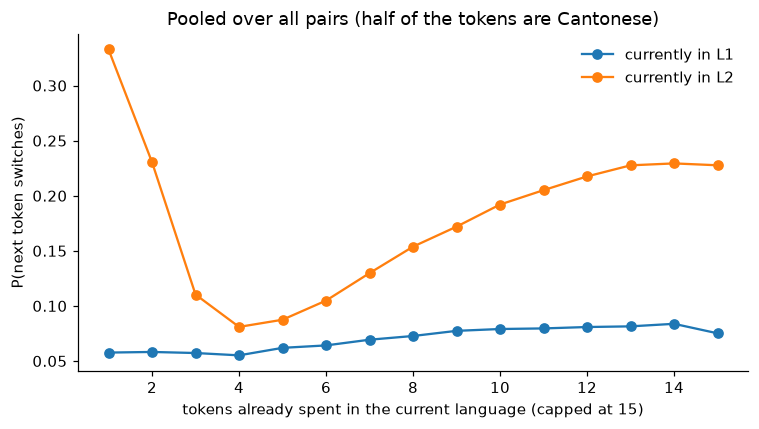

runpos,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
lang,,,,,,,,,,,,,,,
L1,0.058,0.058,0.057,0.055,0.062,0.064,0.069,0.073,0.077,0.079,0.080,0.081,0.081,0.084,0.075
L2,0.333,0.230,0.110,0.081,0.087,0.105,0.130,0.154,0.172,0.192,0.205,0.218,0.228,0.229,0.228


In [5]:
# Run position = how many language-bearing tokens the current run has lasted so far.
lb = T["lang"] != "-"
idx = np.flatnonzero(lb)
L = T["lang"][idx]; R = T["row"][idx]
start = np.ones(len(idx), dtype=bool)
start[1:] = (L[1:] != L[:-1]) | (R[1:] != R[:-1])
k = np.arange(len(idx))
runpos = k - np.maximum.accumulate(np.where(start, k, 0)) + 1
RP = np.zeros(len(T["tok"]), dtype=np.int64); RP[idx] = runpos
CAP = 15
H = pd.DataFrame({"pair": T["pair"][scored], "lang": T["lang"][scored],
                  "runpos": np.minimum(RP[scored], CAP), "sw": sw[scored]})
haz = H.groupby(["lang", "runpos"]).sw.mean().unstack(0)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(haz.index, haz["L1"], "o-", label="currently in L1")
ax.plot(haz.index, haz["L2"], "o-", label="currently in L2")
ax.set_xlabel(f"tokens already spent in the current language (capped at {CAP})")
ax.set_ylabel("P(next token switches)"); ax.legend(frameon=False)
ax.set_title("Pooled over all pairs (half of the tokens are Cantonese)")
plt.tight_layout(); plt.show()
haz.round(3).T

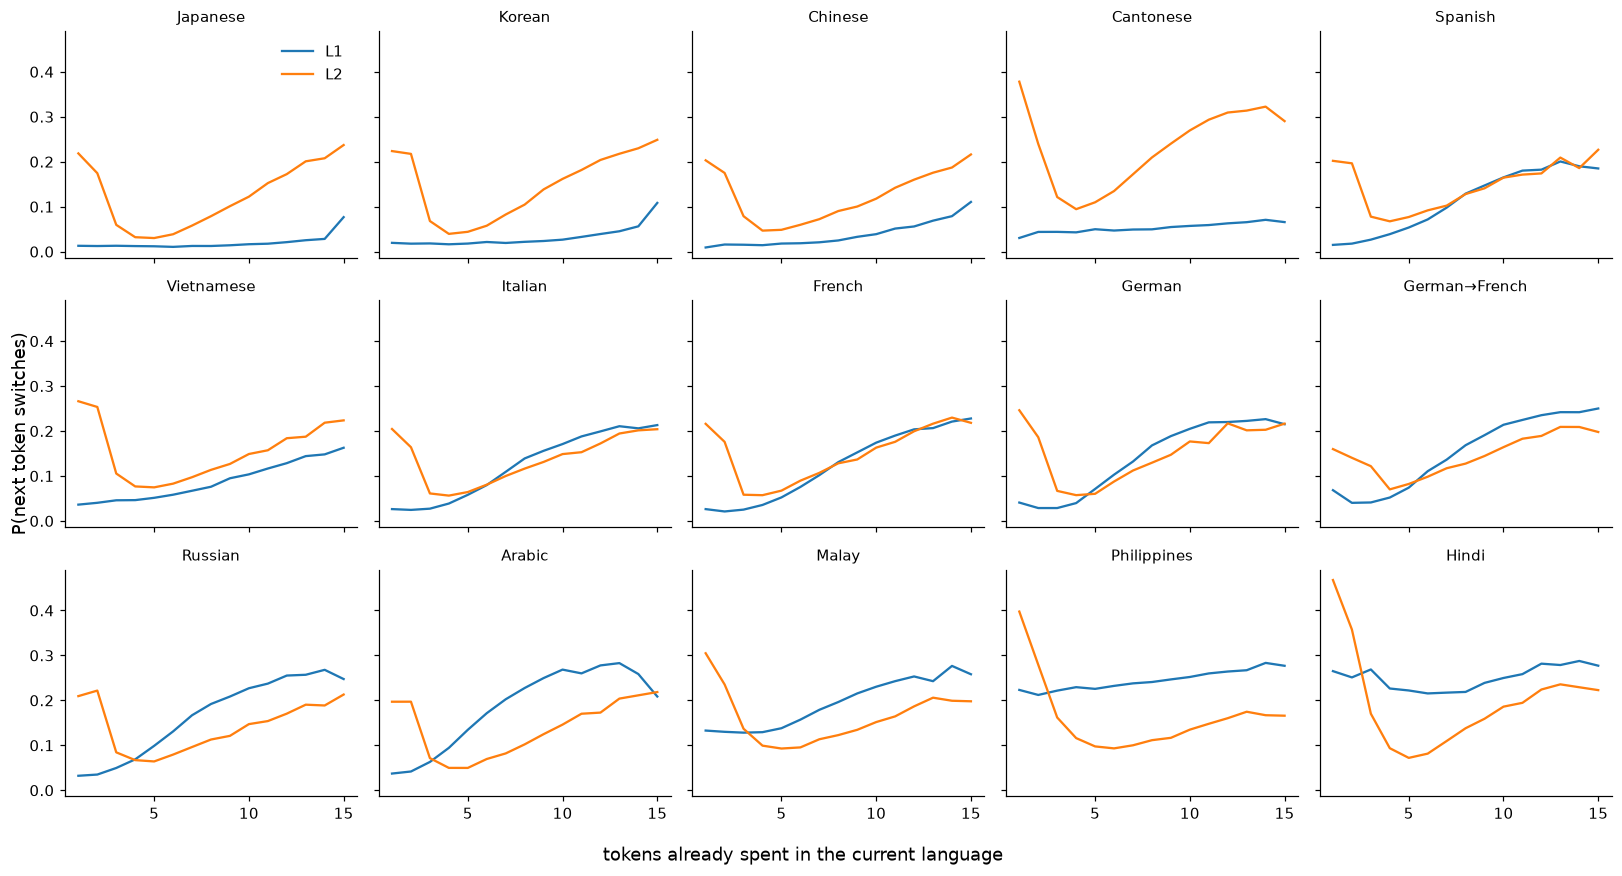

In [6]:
# The same hazard, pair by pair.
pairs = PAIR_ORDER
fig, axes = plt.subplots(3, 5, figsize=(15, 8), sharex=True, sharey=True)
hp = H.groupby(["pair", "lang", "runpos"]).sw.mean()
for ax, p in zip(axes.flat, pairs):
    for lang in ("L1", "L2"):
        s = hp.loc[p, lang]
        ax.plot(s.index, s.values, "-", label=lang)
    ax.set_title(p, fontsize=10)
axes.flat[0].legend(frameon=False)
fig.supxlabel("tokens already spent in the current language"); fig.supylabel("P(next token switches)")
plt.tight_layout(); plt.show()

**Reading it: the pooled curve hides three different patterns.**

- **Leaving L2 is U-shaped in every pair.** A switch back is most likely right after entering (one- and two-word insertions), least likely around the 4th or 5th token, and then climbs again as a longer stretch nears its end.
- **Leaving L1 depends on the script.**
  - **Chinese, Japanese, Korean and Cantonese:** flat and low, so it is close to memoryless.
  - **Latin, Cyrillic and Arabic script** (Spanish, French, Italian, German, Russian, Arabic, Malay, Vietnamese): **it rises steadily**, from about 2% to about 20% over 15 words. The longer someone stays in their first language, the likelier a switch becomes.
  - **Hindi and Tagalog:** flat but high (about 22–28%), because they switch constantly.
- **The pooled curve looks flat only because Cantonese is half the corpus.** The report's §4.3 statement that "first-language runs are close to memoryless" holds for the CJK pairs, not for the Latin-script ones. Run length therefore carries real signal for switching *into* L2 in most pairs, and a per-pair hazard baseline would beat the pooled one there.

### 2b. Where in the conversation?

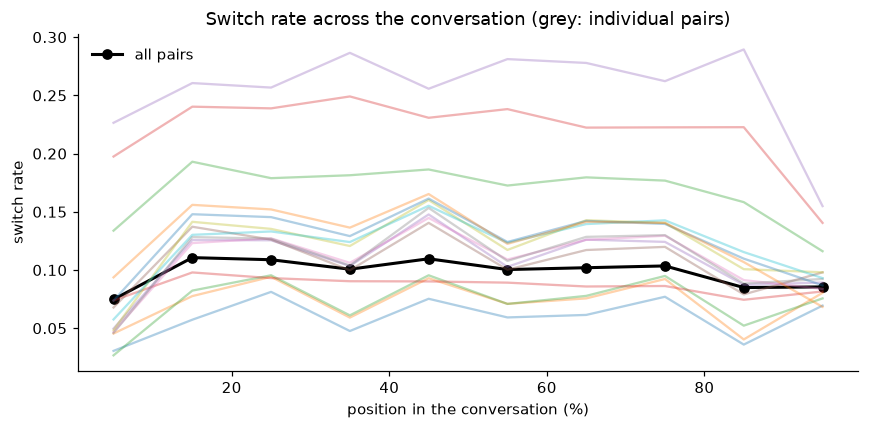

decile,0,1,2,3,4,5,6,7,8,9
pair,,,,,,,,,,
Japanese,3.1,5.7,8.1,4.8,7.5,5.9,6.1,7.7,3.6,6.9
Korean,4.5,7.8,9.4,5.9,9.3,7.1,7.6,9.2,4.0,8.0
Chinese,2.7,8.2,9.5,6.1,9.5,7.1,7.8,9.5,5.2,7.6
Cantonese,7.4,9.8,9.3,9.0,9.0,8.9,8.6,8.6,7.4,8.2
Spanish,5.0,12.6,12.6,10.4,14.8,10.3,12.6,12.4,8.7,8.9
Vietnamese,6.8,13.7,12.6,10.0,14.0,10.0,11.7,12.0,7.9,9.8
Italian,4.7,12.3,12.7,10.6,14.5,10.9,12.6,12.9,9.1,8.4
French,4.6,12.8,12.7,10.4,15.3,10.8,12.8,13.0,8.8,9.2
German,4.8,14.1,13.5,12.1,16.0,11.7,14.3,14.0,10.1,9.8


In [7]:
bins = np.minimum((T["rel"] * 10).astype(int), 9)
P = pd.DataFrame({"pair": T["pair"][scored], "decile": bins[scored], "sw": sw[scored]})
dec = P.groupby(["pair", "decile"]).sw.mean().unstack()
fig, ax = plt.subplots(figsize=(8, 4))
allp = P.groupby("decile").sw.mean()
ax.plot((allp.index + 0.5) * 10, allp.values, "k-o", lw=2, label="all pairs")
for p in PAIR_ORDER:
    ax.plot((dec.columns + 0.5) * 10, dec.loc[p].values, "-", alpha=0.35)
ax.set_xlabel("position in the conversation (%)"); ax.set_ylabel("switch rate")
ax.set_title("Switch rate across the conversation (grey: individual pairs)")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
(dec * 100).round(1).loc[PAIR_ORDER]

### 2c. What comes just before a switch?

In [8]:
# Is the next token punctuation? Switches often sit at clause boundaries.
nxt_punct = np.zeros(len(T["tok"]), dtype=bool)
same_row_next = np.r_[T["row"][1:] == T["row"][:-1], False]
nxt_punct[:-1] = (T["lang"][1:] == "-") & same_row_next[:-1]
B = pd.DataFrame({"pair": T["pair"][scored], "sw": sw[scored], "punct_next": nxt_punct[scored]})
bp = B.groupby(["pair", "sw"]).punct_next.mean().unstack()
bp.columns = ["no switch", "switch"]
bp["ratio"] = bp["switch"] / bp["no switch"]
print("Share of positions followed by punctuation (comma, full stop, ...):")
bp.loc[PAIR_ORDER].style.format({"no switch": "{:.1%}", "switch": "{:.1%}", "ratio": "{:.1f}x"})

Share of positions followed by punctuation (comma, full stop, ...):


,no switch,switch,ratio
pair,,,
Japanese,3.4%,79.3%,23.2x
Korean,1.7%,78.0%,45.7x
Chinese,4.4%,78.8%,18.0x
Cantonese,8.4%,55.8%,6.7x
Spanish,4.3%,78.5%,18.1x
Vietnamese,3.5%,63.4%,18.0x
Italian,4.4%,78.7%,17.8x
French,4.8%,81.4%,16.9x
German,6.6%,80.6%,12.3x


In [9]:
# Words that most often come right before a switch into L2, and the first words of L2 insertions.
# First language-bearing token after each switch (skips punctuation in between).
lb_idx = np.flatnonzero(T["lang"] != "-")
rows = []
for p in PAIR_ORDER:
    m = (T["pair"] == p) & scored & (T["lang"] == "L1")
    before = pd.Series(T["tok"][m]).str.lower(); s = pd.Series(sw[m])
    stats = pd.DataFrame({"n": before.value_counts()})
    stats["rate"] = s.groupby(before.to_numpy()).mean()
    stats = stats[stats.n >= 300].sort_values("rate", ascending=False)
    at = np.flatnonzero(into_l2 & (T["pair"] == p))
    nxt = lb_idx[np.searchsorted(lb_idx, at, side="right")]
    first = pd.Series(T["tok"][nxt]).str.lower().value_counts()
    rows.append({"pair": p,
                 "L1 words most often followed by L2 (switch rate)":
                     ", ".join(f"{t} ({r:.0%})" for t, r in stats.rate.head(5).items()),
                 "most common first word of an L2 stretch": ", ".join(first.head(6).index)})
pd.DataFrame(rows).set_index("pair")

,L1 words most often followed by L2 (switch rate),most common first word of an L2 stretch
pair,,
Japanese,"ね (86%), よ (39%), ど (33%), す (29%), う (24%)","i, you, the, right, it, honestly"
Korean,"죠 (90%), 돼 (67%), 요 (59%), 야 (55%), 데 (48%)","you, right, the, i, it, honestly"
Chinese,"烈 (48%), 彩 (48%), 害 (41%), 题 (39%), 张 (31%)","you, the, i, right, but, it"
Cantonese,"訝 (38%), 吋 (37%), 撼 (36%), 奮 (31%), 援 (30%)","it's, i, but, it, right, the"
Spanish,"años (41%), país (41%), increíble (36%), día (...","you, right, the, i, but, honestly"
Vietnamese,"tới (57%), rồi (51%), vậy (39%), nhanh (33%), ...","you, right, the, especially, honestly, i"
Italian,"interessante (34%), anni (30%), salute (28%), ...","you, right, i, the, but, especially"
French,"soir (51%), incroyable (35%), prochaine (34%),...","you, right, especially, honestly, the, but"
German,"gesehen (52%), spannend (47%), gelesen (45%), ...","you, right, but, especially, honestly, the"


**Reading it.** In most pairs, about 70–80% of switches are followed directly by punctuation, against 2–9% of other tokens, so switches happen at clause boundaries. Tagalog, Hindi and Malay are the exception: only a third to a half of their switches touch punctuation, because they insert single English words mid-clause. Just before a switch into English, the top words are sentence-final particles in Japanese (ね, よ) and Korean (죠, 요), and English stretches most often open with *I*, *you*, *the*, *right* or *honestly*.

## 3. How long do switches last?

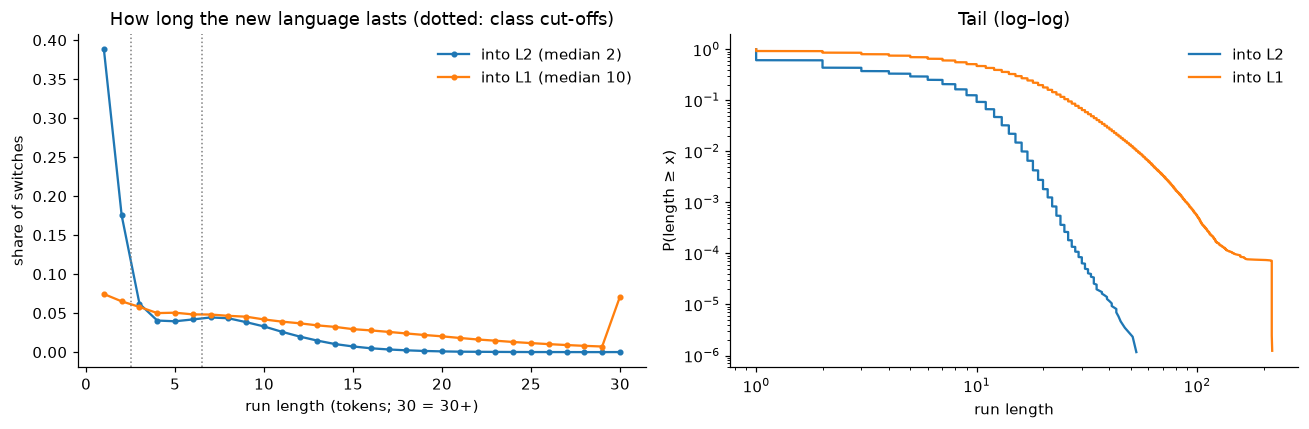

In [10]:
S = pd.DataFrame({"pair": T["pair"][sw], "dir": np.where(T["lang"][sw] == "L1", "into L2", "into L1"),
                  "y_len": T["y_len"][sw], "cls": T["y_dur"][sw],
                  "known": T["dur_known"][sw], "censored": T["censored"][sw]})
closed = S[~S.censored]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for d in ("into L2", "into L1"):
    x = closed[closed.dir == d].y_len
    c = np.bincount(np.minimum(x, 30), minlength=31)[1:] / len(x)
    axes[0].plot(np.arange(1, 31), c, "o-", ms=3, label=f"{d} (median {int(x.median())})")
    v = np.sort(x.to_numpy()); ccdf = 1 - np.arange(len(v)) / len(v)
    axes[1].loglog(v, ccdf, label=d)
for x0 in (2.5, 6.5):
    axes[0].axvline(x0, color="grey", ls=":", lw=1)
axes[0].set_xlabel("run length (tokens; 30 = 30+)"); axes[0].set_ylabel("share of switches")
axes[0].set_title("How long the new language lasts (dotted: class cut-offs)")
axes[1].set_xlabel("run length"); axes[1].set_ylabel("P(length ≥ x)"); axes[1].set_title("Tail (log–log)")
for a in axes: a.legend(frameon=False)
plt.tight_layout(); plt.show()

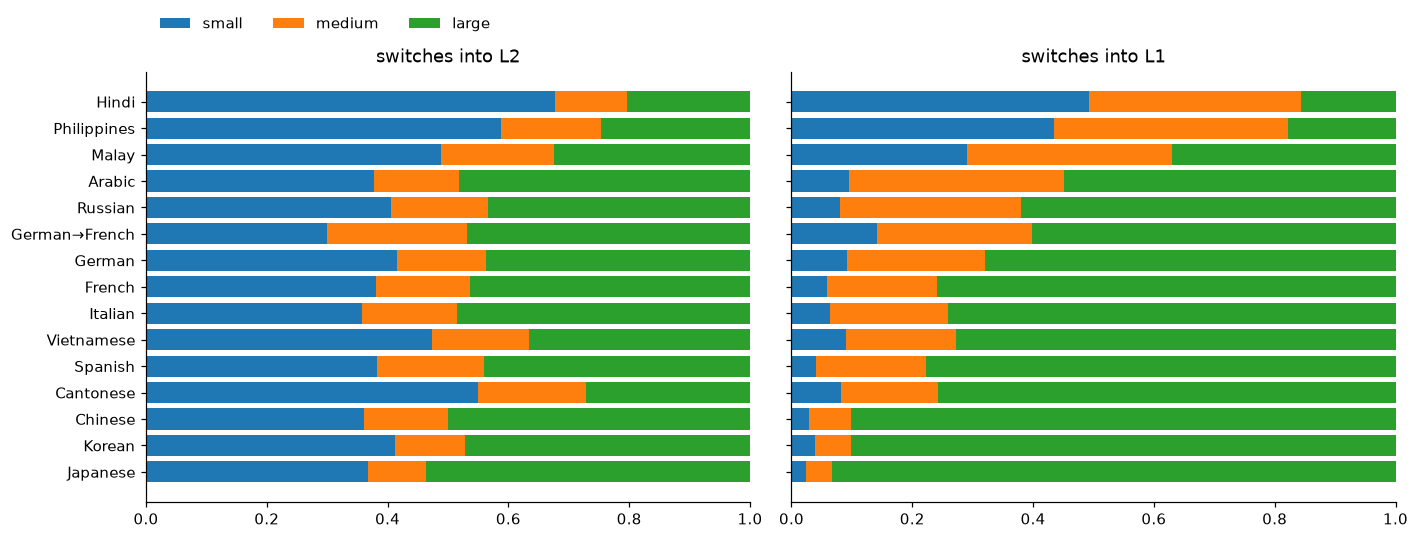

small          medium           large         median length        
dir           into L1 into L2 into L1 into L2 into L1 into L2       into L1 into L2
pair                                                                               
Japanese        0.024   0.367   0.042   0.097   0.934   0.536          22.0     4.0
Korean          0.040   0.412   0.058   0.116   0.902   0.473          18.0     3.0
Chinese         0.029   0.360   0.070   0.140   0.901   0.500          16.0     4.0
Cantonese       0.082   0.550   0.159   0.178   0.758   0.272          13.0     2.0
Spanish         0.041   0.382   0.182   0.176   0.777   0.441           9.0     3.0
Vietnamese      0.091   0.473   0.181   0.161   0.728   0.366          11.0     2.0
Italian         0.063   0.358   0.196   0.156   0.740   0.486           9.0     4.0
French          0.059   0.380   0.181   0.156   0.760   0.464           9.0     3.0
German          0.092   0.416   0.229   0.147   0.679   0.436           8.0     3.0
German→French   0.141   0.300   0.257   0.232   0.601   0.469           8.0     4.0
Russian         0.079   0.405   0.301   0.161   0.620   0.434           7.0     3.0
Arabic          0.096   0.378   0.355   0.141   0.549   0.482           7.0     3.0
Malay           0.290   0.488   0.339   0.188   0.371   0.325           5.0     2.0
Philippines     0.435   0.587   0.387   0.166   0.179   0.247           3.0     2.0
Hindi           0.492   0.678   0.353   0.118   0.156   0.204           3.0     1.0

In [11]:
# Small / Medium / Large by pair and direction (runs whose class is certain).
k = S[S.known]
cls = (k.groupby(["pair", "dir"]).cls.value_counts(normalize=True).unstack().fillna(0)
       [["small", "medium", "large"]])
med = closed.groupby(["pair", "dir"]).y_len.median().rename("median length")
tab = cls.join(med).unstack("dir")
tab = tab.reindex(PAIR_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, d in zip(axes, ("into L2", "into L1")):
    c = cls.xs(d, level="dir").reindex(PAIR_ORDER)
    left = np.zeros(len(c))
    for name in ("small", "medium", "large"):
        ax.barh(c.index, c[name], left=left, label=name); left += c[name].to_numpy()
    ax.set_title(f"switches {d}"); ax.set_xlim(0, 1)
axes[0].legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.06))
plt.tight_layout(); plt.show()
tab.round(3)

In [12]:
# Does keeping cut-off 7+ runs change the class balance?
cmp_ = pd.DataFrame({
    "known (used for training)": S[S.known].cls.value_counts(normalize=True),
    "closed runs only": closed.cls.value_counts(normalize=True)}).loc[["small", "medium", "large"]]
cmp_.style.format("{:.1%}")

,known (used for training),closed runs only
cls,,
small,33.1%,35.8%
medium,18.1%,19.5%
large,48.8%,44.7%


In [13]:
# Words vs XLM-R pieces: the same switches, counted in different units.
pc = pd.read_parquet(PIECE, columns=["first_language", "second_language", "lang", "y_sw", "y_len", "censored"])
pc["pair"] = [pair_name(a, b) for a, b in zip(pc.first_language, pc.second_language)]
n = pc.lang.map(len).to_numpy()
pp = np.repeat(pc.pair.to_numpy(), n)
psw = np.concatenate([np.asarray(x) for x in pc.y_sw]) == 1
plen = np.concatenate([np.asarray(x) for x in pc.y_len])
pcen = np.concatenate([np.asarray(x) for x in pc.censored]).astype(bool)
pl = np.concatenate([np.asarray(x, dtype=object) for x in pc.lang])
m = psw & ~pcen
U = pd.DataFrame({"pair": pp[m], "dir": np.where(pl[m] == "L1", "into L2", "into L1"), "y_len": plen[m]})
units = pd.concat({"words": closed.groupby(["pair", "dir"]).y_len.median(),
                   "pieces": U.groupby(["pair", "dir"]).y_len.median()}, axis=1).unstack("dir")
units.reindex(PAIR_ORDER)

words          pieces        
dir           into L1 into L2 into L1 into L2
pair                                         
Japanese         22.0     4.0    11.0     6.0
Korean           18.0     3.0    11.0     4.0
Chinese          16.0     4.0    10.0     5.0
Cantonese        13.0     2.0     9.0     3.0
Spanish           9.0     3.0    11.0     4.0
Vietnamese       11.0     2.0    11.0     3.0
Italian           9.0     4.0    11.0     5.0
French            9.0     3.0    12.0     4.0
German            8.0     3.0    10.0     4.0
German→French     8.0     4.0     9.0     6.0
Russian           7.0     3.0    10.0     4.0
Arabic            7.0     3.0    10.0     4.0
Malay             5.0     2.0     5.0     3.0
Philippines       3.0     2.0     3.0     2.0
Hindi             3.0     1.0     3.0     2.0

**Reading it.** Switches *into* the second language are mostly short (a word or two), while switches *back* into the first language start long runs. Counting in XLM-R pieces lengthens every run, since a word is 1.3–1.7 pieces, and pushes more switches into Large. The CJK pairs change least, because a piece there often spans one or two characters. Run lengths in CJK are in characters or pieces, so compare them within a script, not across.

## 4. Speaker and conversation attributes

Each conversation's persona and style prompts come from the original SwitchLingua CSVs (joined on `row_id`). Rates here are **averaged per conversation**, so they run a little higher than the token-weighted 9.8% above. The ± column is a 95% interval over conversations.

In [14]:
from huggingface_hub import snapshot_download
from dotenv import dotenv_values
META = ["age", "gender", "education_level", "topic", "tense", "perspective", "cs_ratio",
        "conversation_type", "cs_type", "cs_function"]
snaps = glob.glob(os.path.expanduser(
    "~/.cache/huggingface/hub/datasets--Shelton1013--SwitchLingua_text/snapshots/*/"))
snap = snaps[0] if snaps else snapshot_download(
    "Shelton1013/SwitchLingua_text", repo_type="dataset", allow_patterns=["*.csv"],
    token=dotenv_values(".env").get("HF_TOKEN"))
files = sorted(glob.glob(os.path.join(snap, "*.csv")), key=os.path.basename)
meta = pd.concat([pd.read_csv(f, usecols=META) for f in files], ignore_index=True)
meta.index.name = "row_id"
assert len(meta) == 234_172

# Per-conversation statistics.
per = pd.DataFrame({"row": T["row"], "scored": scored, "sw": sw,
                    "l2": scored & (T["lang"] == "L2"), "l1": scored & (T["lang"] == "L1")})
conv = per.groupby("row")[["scored", "sw", "l1", "l2"]].sum()
conv["switch rate"] = conv.sw / conv.scored.clip(lower=1)
conv["L2 share"] = conv.l2 / (conv.l1 + conv.l2).clip(lower=1)
conv["row_id"] = w.row_id.to_numpy()[conv.index]
conv["pair"] = w.pair.to_numpy()[conv.index]
kl = pd.DataFrame({"row": T["row"][sw], "y_len": T["y_len"][sw], "known": T["dur_known"][sw],
                   "into_l2": T["lang"][sw] == "L1", "large": T["y_dur"][sw] == "large"})
kl = kl[kl.known & kl.into_l2].groupby("row").agg(l2_len=("y_len", "mean"), l2_large=("large", "mean"))
conv = conv.join(kl).join(meta, on="row_id")
AGE = ["8-17", "18-25", "26-35", "56-65", "66+"]
print(f"{len(conv):,} conversations with persona and style attributes")

234,172 conversations with persona and style attributes


In [15]:
def by(attr, order=None):
    g = conv.groupby(attr)
    out = pd.DataFrame({
        "conversations": g.size(),
        "switch rate": g["switch rate"].mean(),
        "± 95%": 1.96 * g["switch rate"].std() / np.sqrt(g.size()),
        "L2 share": g["L2 share"].mean(),
        "mean L2 run (words)": g["l2_len"].mean(),
        "L2 runs that are Large": g["l2_large"].mean()})
    return out.reindex(order) if order else out

fmt = {"conversations": "{:,}", "switch rate": "{:.2%}", "± 95%": "{:.2%}", "L2 share": "{:.1%}",
       "mean L2 run (words)": "{:.2f}", "L2 runs that are Large": "{:.1%}"}
for attr, order in [("age", AGE), ("gender", None), ("education_level", ["High School", "College", "Master", "Doctor"])]:
    display(by(attr, order).style.format(fmt).set_caption(attr))

,conversations,switch rate,± 95%,L2 share,mean L2 run (words),L2 runs that are Large
age,,,,,,
8-17,"46,808",11.67%,0.07%,25.9%,5.16,36.2%
18-25,"46,738",11.57%,0.07%,26.4%,5.34,37.7%
26-35,"46,845",11.25%,0.07%,26.2%,5.41,38.3%
56-65,"46,866",10.74%,0.07%,25.9%,5.58,39.7%
66+,"46,915",10.54%,0.07%,25.6%,5.59,39.7%


,conversations,switch rate,± 95%,L2 share,mean L2 run (words),L2 runs that are Large
gender,,,,,,
Female,"117,222",11.15%,0.04%,26.0%,5.41,38.3%
Male,"116,950",11.16%,0.04%,26.0%,5.43,38.4%


,conversations,switch rate,± 95%,L2 share,mean L2 run (words),L2 runs that are Large
education_level,,,,,,
High School,"58,699",11.29%,0.06%,25.7%,5.26,37.2%
College,"58,823",11.29%,0.06%,26.1%,5.38,37.9%
Master,"58,317",11.02%,0.06%,26.1%,5.50,39.0%
Doctor,"58,333",11.02%,0.06%,26.1%,5.53,39.2%


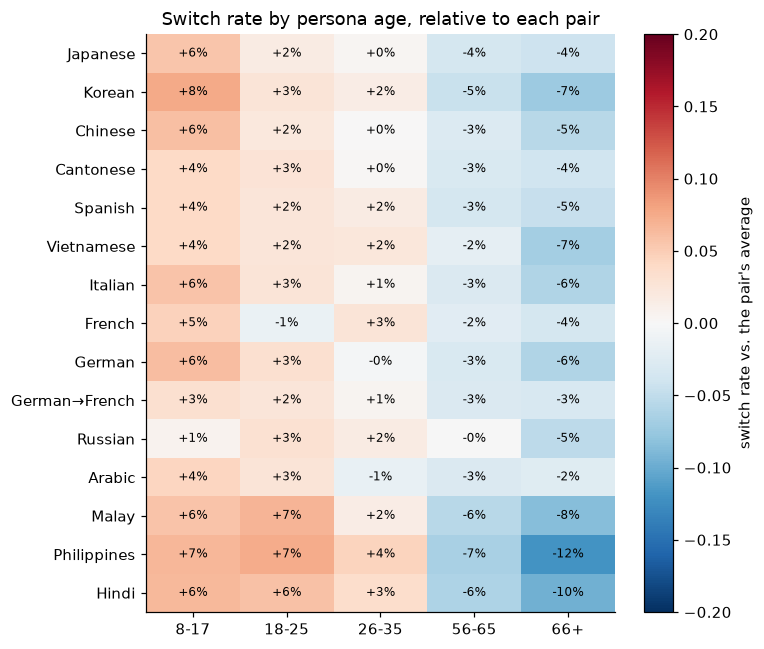

In [16]:
# Age x pair: does the persona's age change switching differently per language?
ap = conv.pivot_table(index="pair", columns="age", values="switch rate").reindex(PAIR_ORDER)[AGE]
rel = ap.div(ap.mean(axis=1), axis=0) - 1        # relative to each pair's own average
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(rel, cmap="RdBu_r", vmin=-0.2, vmax=0.2, aspect="auto")
ax.set_xticks(range(len(AGE)), AGE); ax.set_yticks(range(len(ap)), ap.index)
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        ax.text(j, i, f"{rel.iat[i, j]:+.0%}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="switch rate vs. the pair's average")
ax.set_title("Switch rate by persona age, relative to each pair")
plt.tight_layout(); plt.show()

In [17]:
# The style prompts: requested switch ratio, switch type and function.
for attr, order in [("cs_ratio", ["30%", "50%", "70%"]), ("cs_type", None), ("cs_function", None),
                    ("conversation_type", None), ("topic", None), ("tense", None), ("perspective", None)]:
    tab = by(attr, order)
    if order is None:
        tab = tab.sort_values("switch rate", ascending=False)
    display(tab.style.format(fmt).set_caption(attr))

,conversations,switch rate,± 95%,L2 share,mean L2 run (words),L2 runs that are Large
cs_ratio,,,,,,
30%,"78,375",11.36%,0.05%,28.1%,5.73,41.1%
50%,"78,052",11.27%,0.05%,25.9%,5.35,37.8%
70%,"77,745",10.83%,0.05%,23.9%,5.17,36.1%


,conversations,switch rate,± 95%,L2 share,mean L2 run (words),L2 runs that are Large
cs_type,,,,,,
Extra-sentential / Tag switching,"78,390",13.83%,0.06%,18.3%,3.07,15.0%
Intrasentential,"77,555",11.12%,0.05%,25.4%,4.98,35.4%
Intersentential,"78,227",8.50%,0.04%,34.3%,8.09,63.4%


,conversations,switch rate,± 95%,L2 share,mean L2 run (words),L2 runs that are Large
cs_function,,,,,,
Directive,"39,169",11.35%,0.08%,26.5%,5.41,38.8%
Poetic,"38,982",11.31%,0.08%,25.7%,5.26,36.5%
Expressive,"38,891",11.25%,0.08%,25.9%,5.36,38.1%
Phatic,"39,013",11.16%,0.08%,25.6%,5.27,38.3%
Referential,"38,969",10.95%,0.08%,26.4%,5.63,39.8%
Metalinguistic,"39,148",10.90%,0.08%,25.9%,5.57,38.5%


,conversations,switch rate,± 95%,L2 share,mean L2 run (words),L2 runs that are Large
conversation_type,,,,,,
single_turn,"117,388",11.30%,0.04%,28.6%,6.03,44.1%
multi-turn,"116,784",11.00%,0.04%,23.4%,4.82,32.7%


,conversations,switch rate,± 95%,L2 share,mean L2 run (words),L2 runs that are Large
topic,,,,,,
technology,"25,710",14.02%,0.10%,27.9%,4.65,30.3%
business,"26,327",12.15%,0.10%,26.8%,5.20,36.3%
entertainment,"26,014",11.85%,0.10%,25.8%,4.93,33.8%
sports,"26,083",11.67%,0.10%,25.6%,5.03,34.8%
general,"25,962",11.26%,0.09%,26.2%,5.42,38.4%
science,"25,983",10.82%,0.09%,25.6%,5.57,39.7%
health,"26,121",10.14%,0.09%,26.1%,5.87,42.3%
world,"26,060",9.35%,0.08%,25.1%,6.01,44.6%
nation,"25,912",9.13%,0.08%,25.1%,6.11,45.2%


,conversations,switch rate,± 95%,L2 share,mean L2 run (words),L2 runs that are Large
tense,,,,,,
Present,"77,883",11.60%,0.06%,25.8%,5.18,36.4%
Future,"78,595",11.13%,0.05%,26.7%,5.54,40.1%
Past,"77,694",10.73%,0.05%,25.5%,5.54,38.5%


,conversations,switch rate,± 95%,L2 share,mean L2 run (words),L2 runs that are Large
perspective,,,,,,
Third Person,"116,961",11.15%,0.04%,26.3%,5.48,39.4%
First Person,"117,211",11.15%,0.04%,25.7%,5.35,37.3%


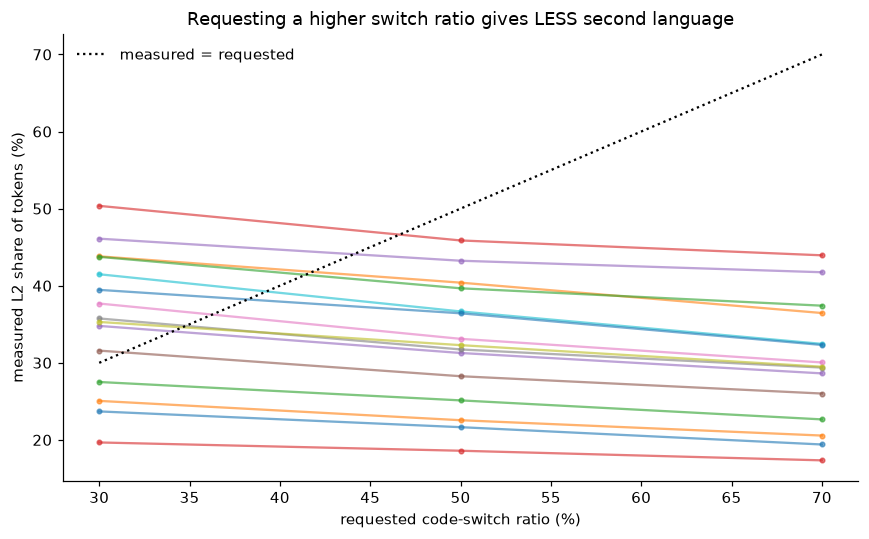

cs_ratio,30%,50%,70%
pair,,,
Japanese,23.7,21.7,19.4
Korean,25.1,22.6,20.6
Chinese,27.5,25.1,22.7
Cantonese,19.7,18.6,17.3
Spanish,34.8,31.3,28.6
Vietnamese,31.6,28.3,26.0
Italian,37.7,33.1,30.0
French,35.8,31.7,29.4
German,35.3,32.3,29.5


In [18]:
# Requested vs measured: does asking for a 70% switch ratio give more L2?
rq = conv.pivot_table(index="pair", columns="cs_ratio", values="L2 share").reindex(PAIR_ORDER)[["30%", "50%", "70%"]]
fig, ax = plt.subplots(figsize=(8, 5))
for p in rq.index:
    ax.plot([30, 50, 70], rq.loc[p] * 100, "-o", ms=3, alpha=0.6)
ax.plot([30, 70], [30, 70], "k:", label="measured = requested")
ax.set_xlabel("requested code-switch ratio (%)"); ax.set_ylabel("measured L2 share of tokens (%)")
ax.set_title("Requesting a higher switch ratio gives LESS second language"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
(rq * 100).round(1)

**Reading it.** The attributes are balanced by design, so each gap below is the generator's response to the prompt. Every interval is small (about ±0.1%), so these gaps are real, **for the generator**.

- **Switch type is by far the strongest lever, and it behaves as its name says.** *Tag switching* gives the most frequent and shortest switches (about 14% of tokens, mean L2 run of 3 words, 15% Large). *Intersentential* gives the rarest and longest (8.5%, 8 words, 63% Large). *Intrasentential* sits between them. That the labels reproduce these definitions is also a check on the labels.
- **Age: older personas switch less often but for longer.** The switch rate falls steadily from 11.7% (8–17) to 10.5% (66+), a 10% relative drop, and mean L2 runs grow from 5.2 to 5.6 words. The heatmap shows the direction is the same in most pairs.
- **Gender makes no difference.** Education has a small effect in the same direction as age: higher education means slightly fewer, longer switches.
- **Topic matters.** Technology prompts switch the most (14.0%, likely English technical vocabulary), and news-like topics (world, nation) the least (about 9%), with longer runs.
- **Single-turn texts carry more second language, in longer runs, than multi-turn dialogues.**
- **The requested ratio (`cs_ratio`) works backwards.** Asking for 70% yields *less* second language (23.9% of tokens) than asking for 30% (28.1%), in every pair, and far from either number. Either the field means something other than its name suggests (for example, the share kept in the first language), or the generator does not follow it. **Don't use it as a label for switching intensity.**

## 5. Takeaways for the model

In [19]:
train = w.split.to_numpy()[T["row"]] == "train"
base = sw[scored & train].mean()
kc = pd.Series(T["y_dur"][sw & T["dur_known"] & train]).value_counts(normalize=True)[["small", "medium", "large"]]
weights = (1 / kc) / (1 / kc).sum() * 3
print(f"switch base rate (train): {base:.2%}  -> about 1 switch every {1/base:.0f} scored tokens")
print(f"positive-class weight for a balanced switch loss: {(1-base)/base:.1f}")
print("duration classes (train, class certain):", ", ".join(f"{c} {v:.1%}" for c, v in kc.items()))
print("inverse-frequency class weights (mean 1):", ", ".join(f"{c} {v:.2f}" for c, v in weights.items()))

switch base rate (train): 9.79%  -> about 1 switch every 10 scored tokens
positive-class weight for a balanced switch loss: 9.2
duration classes (train, class certain): small 33.2%, medium 18.1%, large 48.8%
inverse-frequency class weights (mean 1): small 0.85, medium 1.57, large 0.58


- **Switches are rare.** About one scored token in ten, so accuracy is meaningless; report F1 on the switch class, and weight the loss or tune the threshold.
- **Direction matters more than anything else.** Leaving L2 is highly predictable from run length alone, and entering L2 is not. A model that beats the baselines must do it on the switch *into* L2, from lexical context.
- **Duration is imbalanced, and it differs by direction.** Weight the duration loss (the weights above), and report macro-F1 over the classes.
- **Pairs differ by up to 4× in switch rate.** A single global threshold is not universal, so report per-pair F1 and macro-F1 across pairs.
- **Everything here is synthetic.** Persona and style effects describe the generator, and conclusions about real speakers need real data.